# ESTACIONARIEDAD DE SERIES TEMPORALES

Analizad la estacionariedad de la siguiente serie temporal.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

<Axes: title={'center': 'Annual Livestock'}, xlabel='date'>

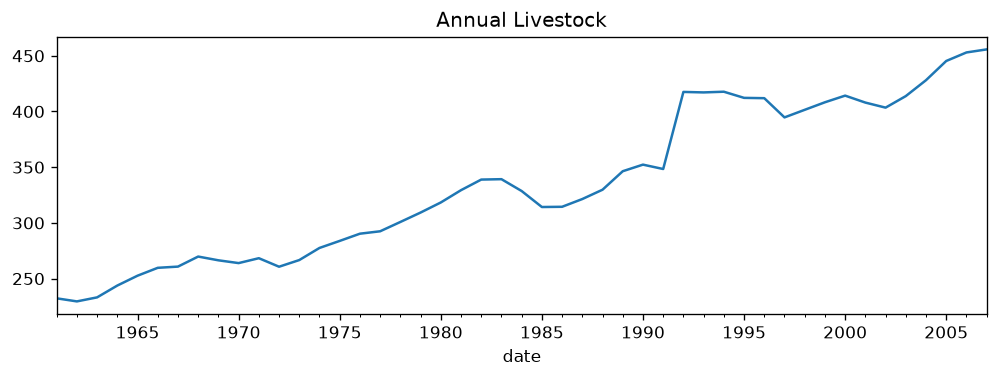

In [2]:
path = 'https://raw.githubusercontent.com/selva86/datasets/master/livestock.csv'
df = pd.read_csv(path, parse_dates=['date'], index_col='date')
fig, axes = plt.subplots(1,1, dpi=120)
df.plot(title='Annual Livestock', figsize=(10,3), legend=None, ax=axes)

In [3]:
df

,value
date,
1961-01-01,232.288994
1962-01-01,229.536258
1963-01-01,233.145936
1964-01-01,243.763684
1965-01-01,252.602916
1966-01-01,259.677371
1967-01-01,260.766892
1968-01-01,269.784084
1969-01-01,266.414974


In [4]:
# ADF test

from statsmodels.tsa.stattools import adfuller
def adf_test(series):
    result = adfuller(series, autolag='AIC')
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {result[1]}')
    for key, value in result[4].items():
        print('Critial Values:')
        print(f'   {key}, {value}')


In [5]:
# KPSS test
from statsmodels.tsa.stattools import kpss
def kpss_test(series, **kw):    
    statistic, p_value, n_lags, critical_values = kpss(series, **kw)
    # Format Output
    print(f'KPSS Statistic: {statistic}')
    print(f'p-value: {p_value}')
    print(f'num lags: {n_lags}')
    print('Critial Values:')
    for key, value in critical_values.items():
        print(f'   {key} : {value}')
    print(f'Result: The series is {"not " if p_value < 0.05 else ""}stationary')


In [6]:
adf_test(df['value'])

ADF Statistic: -0.23838372529910107
p-value: 0.9337890318823665
Critial Values:
   1%, -3.5812576580093696
Critial Values:
   5%, -2.9267849124681518
Critial Values:
   10%, -2.6015409829867675


C:\Users\maren\AppData\Local\Temp\ipykernel_3664\2308964334.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, autolag='AIC')


In [ ]:
# Interpretación del test ADF:
# El estadístico ADF es -0.2384 y el p-valor es 0.9338.
# 
# La hipótesis nula (H0) del test ADF indica que la serie no es estacionaria
# (existe una raíz unitaria).
#
# Como el p-valor (0.9338) es mayor que 0.05, no rechazamos H0.
# Por tanto, no podemos considerar la serie estacionaria.
#
# Además, el estadístico ADF (-0.2384) es mayor que todos los valores críticos:
# 1%: -3.5813
# 5%: -2.9268
# 10%: -2.6015
#
# Por tanto, el test ADF indica que la serie NO es estacionaria.

In [7]:
kpss_test(df['value'])

KPSS Statistic: 1.026377056837458
p-value: 0.01
num lags: 4
Critial Values:
   10% : 0.347
   5% : 0.463
   2.5% : 0.574
   1% : 0.739
Result: The series is not stationary


C:\Users\maren\AppData\Local\Temp\ipykernel_3664\528587488.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  statistic, p_value, n_lags, critical_values = kpss(series, **kw)
C:\Users\maren\AppData\Local\Temp\ipykernel_3664\528587488.py:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, p_value, n_lags, critical_values = kpss(series, **kw)


In [ ]:
# Interpretación del test KPSS:
# El estadístico KPSS es 1.0264 y el p-valor es 0.01.
#
# En el test KPSS, la hipótesis nula (H0) indica que la serie es estacionaria.
#
# Como el p-valor (0.01) es menor que 0.05, rechazamos H0.
# Por tanto, concluimos que la serie no es estacionaria.
#
# Además, el estadístico KPSS (1.0264) es mayor que todos los valores críticos:
# 10%: 0.347
# 5%: 0.463
# 2.5%: 0.574
# 1%: 0.739
#
# Por tanto, el test KPSS confirma que la serie NO es estacionaria.

In [8]:
##diferenciar serie

diferenciada = df.diff()
diferenciada = df.diff().dropna()
diferenciada

,value
date,
1962-01-01,-2.752736
1963-01-01,3.609678
1964-01-01,10.617748
1965-01-01,8.839232
1966-01-01,7.074455
1967-01-01,1.089521
1968-01-01,9.017192
1969-01-01,-3.369110
1970-01-01,-2.497227


<Axes: xlabel='date'>

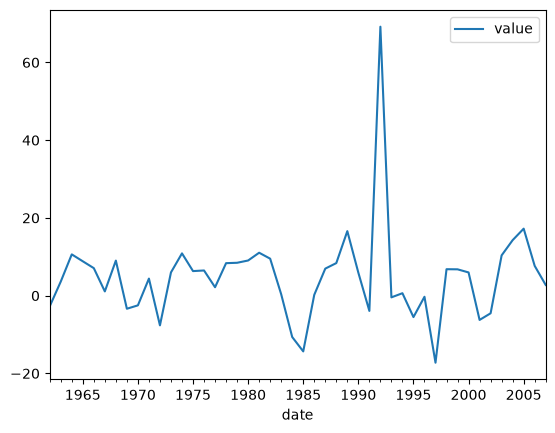

In [13]:
diferenciada.plot()

In [9]:
adf_test(diferenciada['value'])

ADF Statistic: -6.465207693625788
p-value: 1.4108475574140927e-08
Critial Values:
   1%, -3.584828853223594
Critial Values:
   5%, -2.9282991495198907
Critial Values:
   10%, -2.6023438271604937


C:\Users\maren\AppData\Local\Temp\ipykernel_3664\2308964334.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, autolag='AIC')


In [ ]:
# Interpretación del test ADF:
# El estadístico ADF es -6.4652 y el p-valor es 1.41e-08.
# Como el p-valor es menor que 0.05, rechazamos la hipótesis nula (H0).
# H0: la serie no es estacionaria.
# Por tanto, concluimos que la serie diferenciada es estacionaria.
#
# Además, el estadístico ADF (-6.4652) es menor que los valores críticos:
# 1%: -3.5848
# 5%: -2.9283
# 10%: -2.6023
#
# Por tanto, se rechaza H0 incluso al nivel de significación del 1%.

In [10]:
kpss_test(diferenciada['value'])

KPSS Statistic: 0.05036524844823132
p-value: 0.1
num lags: 0
Critial Values:
   10% : 0.347
   5% : 0.463
   2.5% : 0.574
   1% : 0.739
Result: The series is stationary


C:\Users\maren\AppData\Local\Temp\ipykernel_3664\528587488.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  statistic, p_value, n_lags, critical_values = kpss(series, **kw)
C:\Users\maren\AppData\Local\Temp\ipykernel_3664\528587488.py:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, p_value, n_lags, critical_values = kpss(series, **kw)


In [12]:
# Interpretación del test KPSS:
# El estadístico KPSS es 0.0504 y el p-valor es 0.1.
# En el test KPSS, la hipótesis nula (H0) indica que la serie es estacionaria.
#
# Como el p-valor es mayor que 0.05, no rechazamos la hipótesis nula.
# Por tanto, concluimos que la serie es estacionaria.
#
# Además, el estadístico KPSS (0.0504) es menor que todos los valores críticos:
# 10%: 0.347
# 5%: 0.463
# 2.5%: 0.574
# 1%: 0.739
#
# Por tanto, el test KPSS confirma que la serie diferenciada es estacionaria.
#
# El InterpolationWarning indica que el p-valor real es superior al máximo
# disponible en la tabla (0.1), por lo que no supone un problema.
#
# El FutureWarning no es un error. Es un aviso de statsmodels sobre un
# cambio futuro en la forma de devolver los resultados.